# Boston Housing Data Analysis — Peer Graded Assignment

Author: Daniil Kozlov

**Scenario:** As a Data Scientist in a real-estate agency in Boston, I analyze U.S. Census housing data to answer four management questions:
1. Is there a significant difference in median home value for houses bounded by the Charles River vs. not?
2. Is there a difference in median home values across groups by proportion of owner-occupied units built before 1940 (AGE)?
3. Is there a relationship between nitric oxide concentration (NOX) and the proportion of non-retail business acres (INDUS)?
4. What is the impact of weighted distance to the five Boston employment centres (DIS) on median home value (MEDV)?

In [1]:
%pip install seaborn statsmodels

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")

<ipython-input-2-e9ffe8c61275>:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


## Load the dataset

In [3]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv"
try:
    from pyodide.http import pyfetch   # JupyterLite (Pyodide) environment
    resp = await pyfetch(url)
    with open("boston_housing.csv", "wb") as f:
        f.write(await resp.bytes())
    boston_df = pd.read_csv("boston_housing.csv")
except ImportError:                    # regular Jupyter environment
    boston_df = pd.read_csv(url)
if "Unnamed: 0" in boston_df.columns:
    boston_df = boston_df.drop(columns=["Unnamed: 0"])

# Task 1: Explore the data

### Q1. First five rows

In [4]:
boston_df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


### Q2. Data types of each column

In [5]:
boston_df.dtypes

CRIM       float64
ZN         float64
INDUS      float64
CHAS       float64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD        float64
TAX        float64
PTRATIO    float64
LSTAT      float64
MEDV       float64
dtype: object

### Q3. Missing values in each column

In [6]:
boston_df.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
LSTAT      0
MEDV       0
dtype: int64

**Interpretation:** There are no missing values, so no imputation is needed.

### Q4. Duplicate rows

In [7]:
boston_df.duplicated().sum()

0

**Interpretation:** There are no duplicate records in the dataset.

### Q5. Correlation matrix

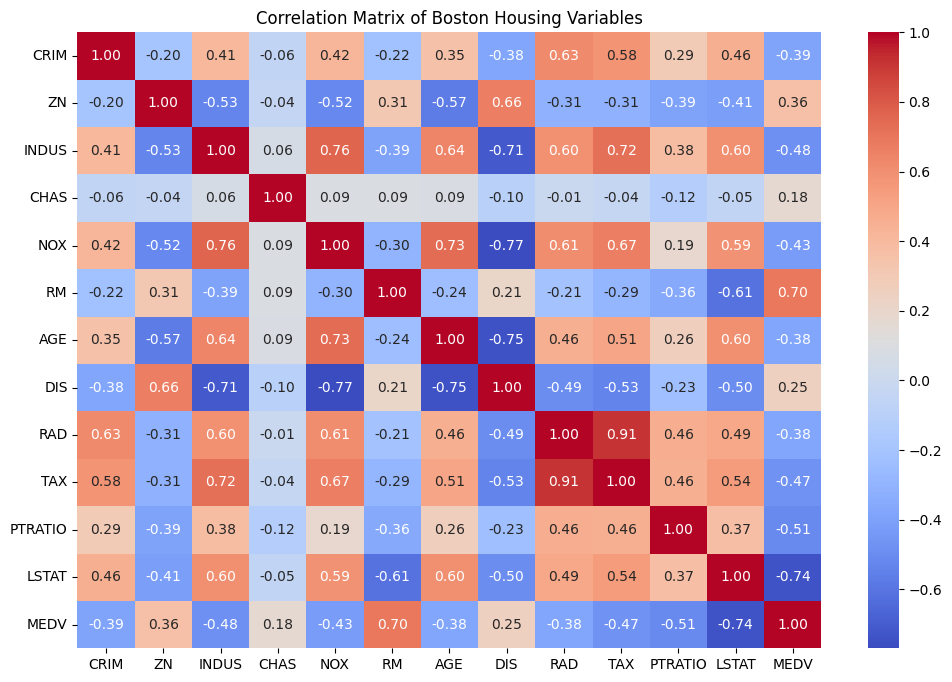

In [8]:
corr = boston_df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Boston Housing Variables")
plt.show()

**Interpretation:** MEDV is strongly negatively correlated with LSTAT and positively with RM. NOX and INDUS show a strong positive correlation, which is examined further in Task 3.

# Task 2: Descriptive statistics and visualizations

### Q6. Summary statistics

In [9]:
boston_df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


### Q7. Boxplot of Median value of owner-occupied homes (MEDV)

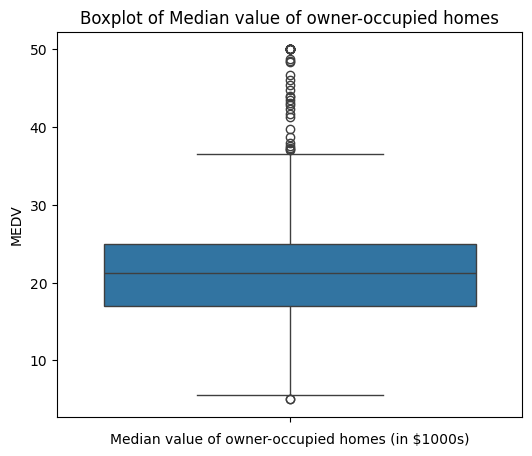

In [10]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=boston_df["MEDV"])
plt.title("Boxplot of Median value of owner-occupied homes")
plt.xlabel("Median value of owner-occupied homes (in $1000s)")
plt.show()

**Interpretation:** The median home value is about 21 ($1000s), and most values lie between roughly 17 and 25 ($1000s). There are several high-value outliers above ~37, so the distribution is right-skewed rather than symmetric.

### Q8. Bar plot of the Charles River variable (CHAS)

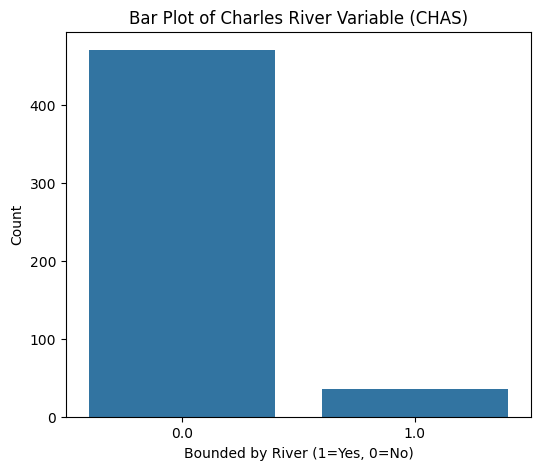

CHAS
0.0    471
1.0     35
Name: count, dtype: int64

In [11]:
plt.figure(figsize=(6, 5))
sns.countplot(x="CHAS", data=boston_df)
plt.title("Bar Plot of Charles River Variable (CHAS)")
plt.xlabel("Bounded by River (1=Yes, 0=No)")
plt.ylabel("Count")
plt.show()
boston_df["CHAS"].value_counts()

**Interpretation:** The vast majority of tracts are not bounded by the Charles River; only a small fraction (about 7%) are next to the river.

### Q9. Boxplot of MEDV vs. AGE groups (35 years and younger, between 35 and 70 years, 70 years and older)

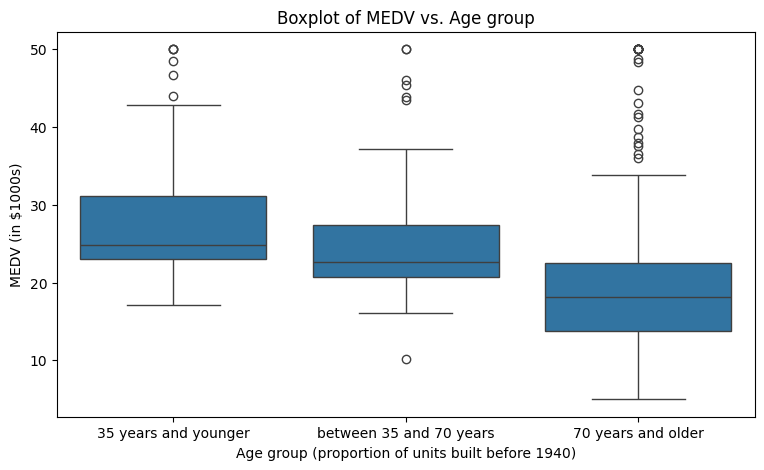

In [12]:
boston_df.loc[boston_df["AGE"] <= 35, "age_group"] = "35 years and younger"
boston_df.loc[(boston_df["AGE"] > 35) & (boston_df["AGE"] < 70), "age_group"] = "between 35 and 70 years"
boston_df.loc[boston_df["AGE"] >= 70, "age_group"] = "70 years and older"

plt.figure(figsize=(9, 5))
sns.boxplot(x="age_group", y="MEDV", data=boston_df,
            order=["35 years and younger", "between 35 and 70 years", "70 years and older"])
plt.title("Boxplot of MEDV vs. Age group")
plt.xlabel("Age group (proportion of units built before 1940)")
plt.ylabel("MEDV (in $1000s)")
plt.show()

**Interpretation:** The group with the oldest housing stock (70 years and older) has the lowest median home value, while the youngest group (35 years and younger) has the highest. Variability and outliers differ between the groups.

### Q10. Scatter plot of NOX vs. INDUS

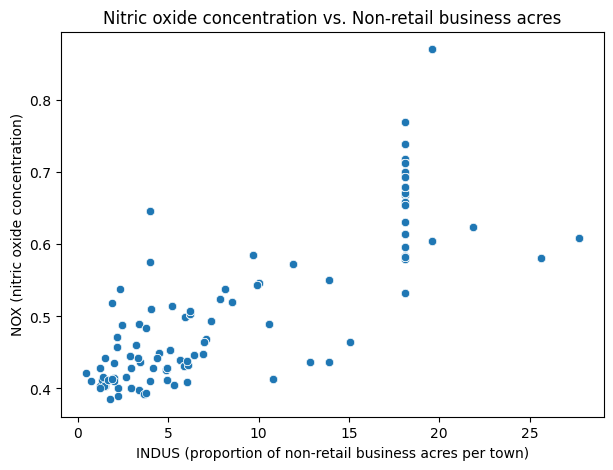

In [13]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x="INDUS", y="NOX", data=boston_df)
plt.title("Nitric oxide concentration vs. Non-retail business acres")
plt.xlabel("INDUS (proportion of non-retail business acres per town)")
plt.ylabel("NOX (nitric oxide concentration)")
plt.show()

**Interpretation:** There is a clear positive relationship: towns with a higher proportion of non-retail business (industrial) acres tend to have higher nitric oxide concentrations.

### Q11. Histogram of the pupil-to-teacher ratio (PTRATIO)

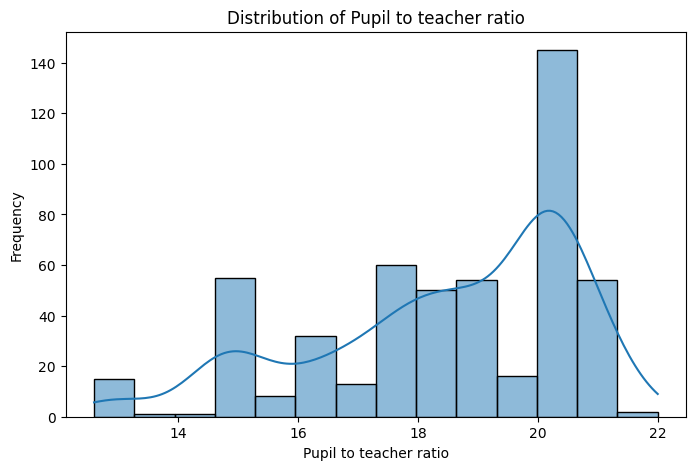

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(boston_df["PTRATIO"], kde=True)
plt.title("Distribution of Pupil to teacher ratio")
plt.xlabel("Pupil to teacher ratio")
plt.ylabel("Frequency")
plt.show()

**Interpretation:** The distribution is left-skewed with a pronounced peak around 20–21. Far fewer towns have a ratio below 15 than above 20.

# Task 3: Hypothesis testing (α = 0.05)

### Q12. Is there a significant difference in MEDV of houses bounded by the Charles River or not? (Levene's test + T-test)

**Levene's test:**
- H₀: The variances of MEDV are equal for both groups
- H₁: The variances of MEDV are not equal for both groups

In [15]:
river = boston_df[boston_df["CHAS"] == 1]["MEDV"]
no_river = boston_df[boston_df["CHAS"] == 0]["MEDV"]
levene_stat, levene_p = scipy.stats.levene(river, no_river, center="mean")
print("Levene statistic:", levene_stat, " p-value:", levene_p)
equal_var = levene_p >= 0.05
print("Assume equal variances:", equal_var)

Levene statistic: 8.75190489604598  p-value: 0.003238119367639829
Assume equal variances: False


### Q13. T-test for independent samples

- H₀: The mean MEDV is the same for houses bounded and not bounded by the Charles River
- H₁: The mean MEDV is different for the two groups

In [16]:
t_stat, t_p = scipy.stats.ttest_ind(river, no_river, equal_var=equal_var)
print("t-statistic:", t_stat, " p-value:", t_p)
print("Reject H0" if t_p < 0.05 else "Fail to reject H0")

t-statistic: 3.113291312794837  p-value: 0.003567170098137517
Reject H0


**Conclusion:** The p-value is less than 0.05, so we reject H₀: there is a statistically significant difference in median home values between houses bounded by the Charles River and those that are not (river-side homes are more valuable on average).

### Q14. Is there a difference in MEDV for each proportion of owner-occupied units built before 1940? (ANOVA)

- H₀: The means of MEDV are equal across all three age groups
- H₁: At least one age group has a different mean MEDV

In [17]:
low = boston_df[boston_df["age_group"] == "35 years and younger"]["MEDV"]
mid = boston_df[boston_df["age_group"] == "between 35 and 70 years"]["MEDV"]
high = boston_df[boston_df["age_group"] == "70 years and older"]["MEDV"]
f_stat, f_p = scipy.stats.f_oneway(low, mid, high)
print("F-statistic:", f_stat, " p-value:", f_p)
print("Reject H0" if f_p < 0.05 else "Fail to reject H0")

F-statistic: 36.40764999196599  p-value: 1.7105011022702984e-15
Reject H0


**Conclusion:** The p-value is less than 0.05, so we reject H₀: at least one age group has a significantly different mean home value.

### Q15. Is there a relationship between NOX and INDUS? (Pearson correlation)

- H₀: There is no linear relationship between NOX and INDUS
- H₁: There is a linear relationship between NOX and INDUS

In [18]:
r, p = scipy.stats.pearsonr(boston_df["NOX"], boston_df["INDUS"])
print("Pearson r:", r, " p-value:", p)
print("Reject H0" if p < 0.05 else "Fail to reject H0")

Pearson r: 0.7636514469209192  p-value: 7.913361061210442e-98
Reject H0


**Conclusion:** The p-value is less than 0.05 and r ≈ 0.76, so we reject H₀: there is a strong, statistically significant positive linear relationship between nitric oxide concentration and the proportion of non-retail business acres.

### Q16. What is the impact of an additional weighted distance to the five Boston employment centres (DIS) on MEDV? (Regression analysis)

- H₀: β₁ = 0 (DIS has no effect on MEDV)
- H₁: β₁ ≠ 0 (DIS has an effect on MEDV)

In [19]:
X = sm.add_constant(boston_df["DIS"])
y = boston_df["MEDV"]
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        19:22:48   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

**Conclusion:** The p-value for the DIS coefficient is less than 0.05, so we reject H₀. The coefficient is positive (≈ 1.09): each additional unit of weighted distance to the employment centres is associated with an increase of about $1,090 in median home value. R² is low (≈ 0.06), so DIS alone explains only a small part of the variation in MEDV.